In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt



In [2]:
PROJECT_DIR = Path.cwd()

RAW_FILE = (
      PROJECT_DIR
      / "data"
      / "raw"
      / "World-Stock-Prices-Dataset.csv"
  )

PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

APPLE_FILE = PROCESSED_DIR / "apple_stock_prices.csv"

In [3]:
columns_to_use = [
      "Date",
      "Open",
      "High",
      "Low",
      "Close",
      "Volume",
      "Ticker",
      "Industry_Tag",
  ]

stocks = pd.read_csv(RAW_FILE, usecols=columns_to_use)

print("Antall rader:", len(stocks))
stocks.head()

Antall rader: 310122


,Date,Open,High,Low,Close,Volume,Ticker,Industry_Tag
0,2025-07-03 00:00:00-04:00,6.630000,6.740000,6.615000,6.640000,4209664.0,PTON,fitness
1,2025-07-03 00:00:00-04:00,106.750000,108.370003,106.330101,107.339996,560190.0,CROX,footwear
2,2025-07-03 00:00:00-04:00,122.629997,123.050003,121.550003,121.930000,36600.0,ADDYY,apparel
3,2025-07-03 00:00:00-04:00,221.705002,224.009995,221.360001,223.410004,29295154.0,AMZN,e-commerce
4,2025-07-03 00:00:00-04:00,212.145004,214.649994,211.810104,213.550003,34697317.0,AAPL,technology


In [4]:
stocks["Date"] = (pd.to_datetime(stocks["Date"], utc=True).dt.normalize())

stocks = (stocks.sort_values(["Ticker", "Date"]).drop_duplicates(subset=["Ticker", "Date"], keep="last")).reset_index(drop=True)

print(stocks.shape)



(306445, 8)


In [5]:
apple = (
    stocks[stocks["Ticker"] == "AAPL"]
    .copy()
    .sort_values("Date")
    .reset_index(drop=True)
)

apple.to_csv(
    APPLE_FILE,
    index=False
)

print("Antall Apple-rader:", len(apple))
print("Fra:", apple["Date"].min())
print("Til:", apple["Date"].max())
print("Lagret i:", APPLE_FILE)

apple.head()

Antall Apple-rader: 6408
Fra: 2000-01-03 00:00:00+00:00
Til: 2025-07-03 00:00:00+00:00
Lagret i: c:\Users\47908\Documents\GitHub\stock-direction-prediction\data\processed\apple_stock_prices.csv


,Date,Open,High,Low,Close,Volume,Ticker,Industry_Tag
0,2000-01-03 00:00:00+00:00,0.794800,0.852586,0.770643,0.848323,535796800.0,AAPL,technology
1,2000-01-04 00:00:00+00:00,0.820377,0.838376,0.766854,0.776801,512377600.0,AAPL,technology
2,2000-01-05 00:00:00+00:00,0.786273,0.837902,0.780590,0.788168,778321600.0,AAPL,technology
3,2000-01-06 00:00:00+00:00,0.804273,0.810904,0.719961,0.719961,767972800.0,AAPL,technology
4,2000-01-07 00:00:00+00:00,0.731329,0.765433,0.723751,0.754065,460734400.0,AAPL,technology


In [6]:
other_stocks = stocks[stocks["Ticker"] != "AAPL"].copy()

other_stocks["Stock_Return_1d"] = (
    other_stocks
    .groupby("Ticker")["Close"]
    .pct_change(fill_method=None)
)

technology_return = other_stocks[
    other_stocks["Industry_Tag"] == "technology"].groupby("Date")["Stock_Return_1d"].mean().rename("Technology_Return_1d")

food_return = (other_stocks [other_stocks["Industry_Tag"].isin(["food"])]).groupby("Date")["Stock_Return_1d"].mean().rename("Food_Return_1d")

market_return = (other_stocks.groupby("Date")["Stock_Return_1d"].mean().rename("Market_Return_1d"))

sector_data = pd.concat([technology_return, food_return, market_return], axis=1).reset_index()

apple = apple.merge(sector_data, on="Date", how="left")


In [7]:
apple["Return_1d"] = apple["Close"].pct_change(1)
apple["Return_5d"] = apple["Close"].pct_change(5)

apple["Intraday_Return"] = (
    (apple["Close"] - apple["Open"])
    / apple["Open"]
)

apple["Price_Range"] = (
    (apple["High"] - apple["Low"])
    / apple["Open"]
)

apple["Volume_Change"] = ( apple["Volume"].pct_change())

apple["MA_5_Ratio"] = (
    apple["Close"]
    / apple["Close"].rolling(5).mean()
    - 1
)

apple["MA_20_Ratio"] = (
    apple["Close"]
    / apple["Close"].rolling(20).mean()
    - 1
)

# Sektortrender
apple["Technology_Trend_5d"] = (
    apple["Technology_Return_1d"]
    .rolling(5)
    .mean()
)

apple["Food_Trend_5d"] = (
    apple["Food_Return_1d"]
    .rolling(5)
    .mean()
)

apple["Market_Trend_5d"] = (
    apple["Market_Return_1d"]
    .rolling(5)
    .mean()
)

# Viser hvordan sammenhengen mellom Apple og teknologi
# forandrer seg gjennom ulike tidsperioder
apple["Apple_Tech_Correlation_60d"] = (
    apple["Return_1d"]
    .rolling(60)
    .corr(apple["Technology_Return_1d"])
)

# Det modellen skal forutsi
apple["Next_Close"] = apple["Close"].shift(-1)

apple["Target"] = (
    apple["Next_Close"] > apple["Close"]
).astype("Int64")

apple.loc[
    apple["Next_Close"].isna(),
    "Target"
] = pd.NA



In [8]:
feature_columns = [
    "Return_1d",
    "Return_5d",
    "Intraday_Return",
    "Price_Range",
    "Volume_Change",
    "MA_5_Ratio",
    "MA_20_Ratio",
    "Technology_Return_1d",
    "Food_Return_1d",
    "Market_Return_1d",
    "Technology_Trend_5d",
    "Food_Trend_5d",
    "Market_Trend_5d",
    "Apple_Tech_Correlation_60d"
]

model_data = (
    apple
    .replace([np.inf, -np.inf], np.nan)
    .dropna(subset=feature_columns + ["Target"])
    .reset_index(drop=True)
)

X = model_data[feature_columns]
y = model_data["Target"].astype(int)

print("Antall rader til modellen:", len(model_data))
print(y.value_counts(normalize=True))

Antall rader til modellen: 6347
Target
1    0.523082
0    0.476918
Name: proportion, dtype: float64


In [9]:
train_end = int(len(model_data) * 0.70)
verify_end = int(len(model_data) * 0.85)

X_train = X.iloc[:train_end]
y_train = y.iloc[:train_end]

X_verify = X.iloc[train_end:verify_end]
y_verify = y.iloc[train_end:verify_end]

X_test = X.iloc[verify_end:]
y_test = y.iloc[verify_end:]

print("Trening:", X_train.shape)
print("Verifisering:", X_verify.shape)
print("Testing:", X_test.shape)

print(
    "Treningsperiode:",
    model_data["Date"].iloc[0],
    "til",
    model_data["Date"].iloc[train_end - 1]
)

Trening: (4442, 14)
Verifisering: (952, 14)
Testing: (953, 14)
Treningsperiode: 2000-03-29 00:00:00+00:00 til 2017-11-21 00:00:00+00:00


In [10]:
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    confusion_matrix
)

In [11]:
models = {
    "Dummy": DummyClassifier(
        strategy="most_frequent"
    ),

    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            max_iter=1000,
            random_state=42
        ))
    ]),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        max_depth=8,
        min_samples_leaf=10,
        max_features="sqrt",
        class_weight="balanced",
        n_jobs=-1,
        random_state=42
    )
}

results = []

for name, model in models.items():
    model.fit(X_train, y_train)

    predictions = model.predict(X_verify)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(
            y_verify,
            predictions
        ),
        "Balanced accuracy":
            balanced_accuracy_score(
                y_verify,
                predictions
            ),
        "F1": f1_score(
            y_verify,
            predictions,
            zero_division=0
        )
    })

results_df = pd.DataFrame(results)
results_df

,Model,Accuracy,Balanced accuracy,F1
0,Dummy,0.539916,0.500000,0.701228
1,Logistic Regression,0.540966,0.519033,0.651237
2,Random Forest,0.504202,0.495452,0.568556


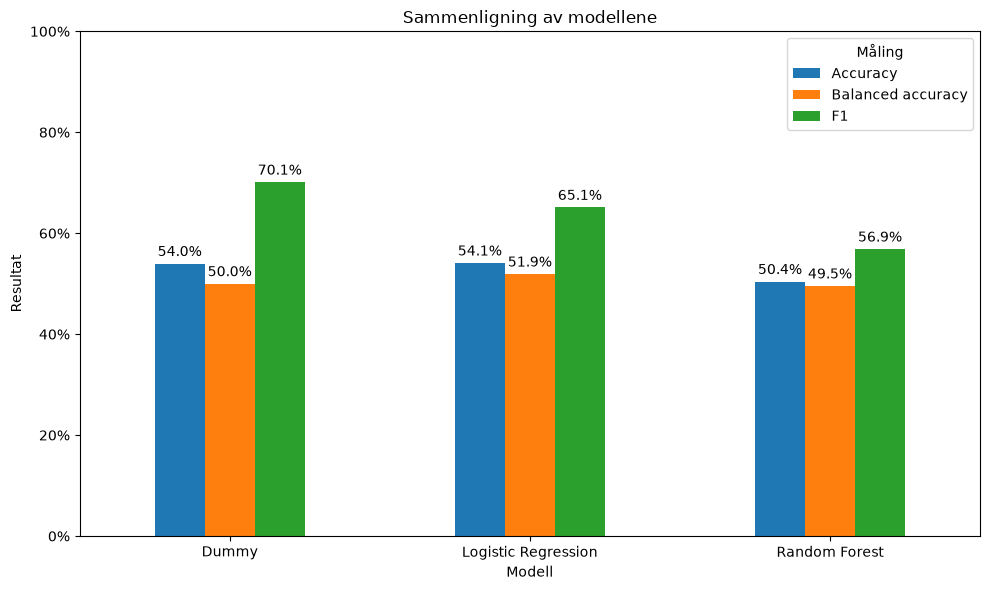

In [12]:
from matplotlib.ticker import PercentFormatter

plot_data = (
    results_df
    .set_index("Model")[
        [
            "Accuracy",
            "Balanced accuracy",
            "F1"
        ]
    ]
    * 100
)

ax = plot_data.plot(
    kind="bar",
    figsize=(10, 6),
    rot=0
)

ax.set_title("Sammenligning av modellene")
ax.set_xlabel("Modell")
ax.set_ylabel("Resultat")
ax.set_ylim(0, 100)

ax.yaxis.set_major_formatter(
    PercentFormatter(100)
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.1f%%",
        padding=3
    )

plt.legend(title="Måling")
plt.tight_layout()
plt.show()